# 1D GMM - One Dimensional Gaussian Mixture Models

So, let's say we have a random variable. This could be something like - 
1. Number of times a user checks his/her phone
2. Number of orders received on a particular product etc.

If we plot the distribution of this variable, We would typically expect it to have a bell curve a.k.a normally distributed. But let's say there is another actor (or a group of actors involved) doing the same action - but at different frequency. Then this would appear as another normal distribution. So, the distribution could look like it has two peaks one at the regular expected mean and another from this new process. 

These two distributions when blended together (mixed) makes a mixture model where both of them are Gaussian (assumed to be, in reality it could be any distribution mixed with Gaussian).

## This notebook
For simplicity, we are going to assume both the distributions are going to be normal. Because I want to learn about 1D-GMM (duh). ;)

## Imports

In [17]:
# imports
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.express as px
import seaborn as sns
from sklearn.mixture import GaussianMixture

## Helper methods

In [3]:
def get_kde_plot(series):
    fig, ax = plt.subplots(1, 1, figsize=(6, 6))
    plot = sns.kdeplot(x=series, ax=ax)
    ax.grid(True, alpha=0.3)
    plt.title("Kernel Density Estimate")
    return plot

Let's first generate 2 different Gaussian distributions and see how they individually look

In [4]:
# first set the random seed so the datasets we generate are deterministic until I change the random seed
rng = np.random.default_rng(seed=42)

In [5]:
g1 = rng.normal(1, 1, 100)
g2 = rng.normal(5, 1, 100)

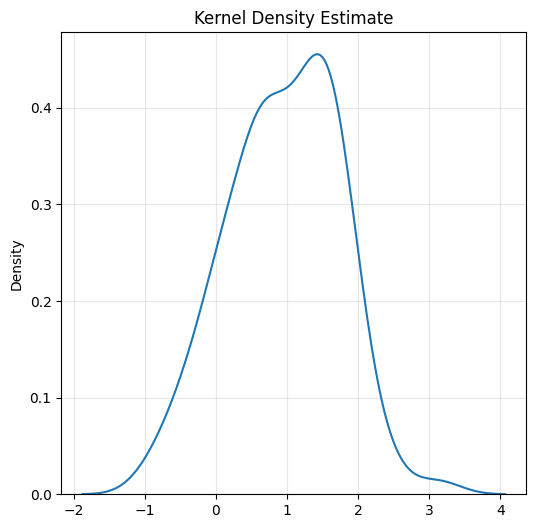

In [6]:
get_kde_plot(g1);

<Axes: title={'center': 'Kernel Density Estimate'}, ylabel='Density'>

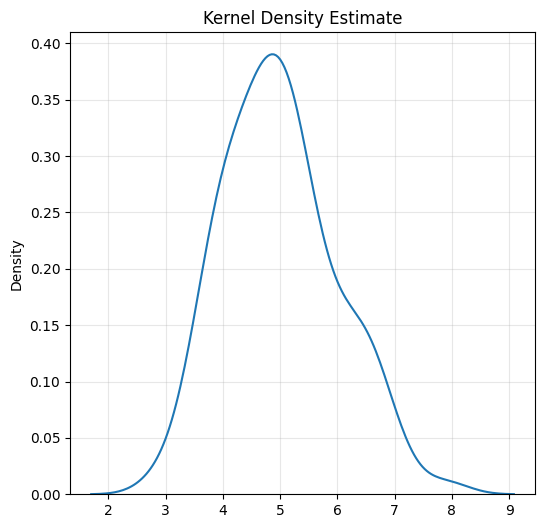

In [7]:
get_kde_plot(g2)

In [8]:
input_signal = np.concatenate([g1, g2])

<Axes: title={'center': 'Kernel Density Estimate'}, ylabel='Density'>

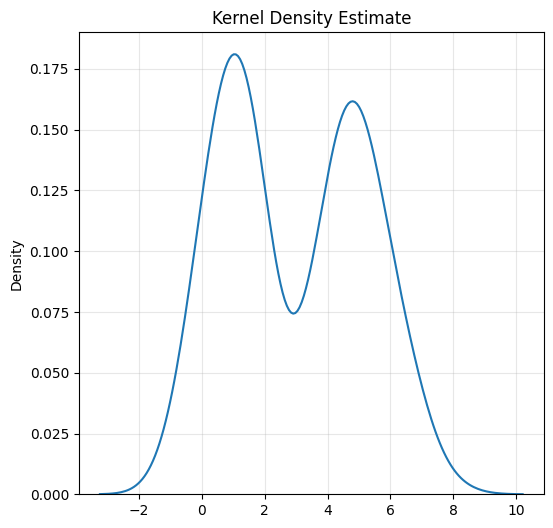

In [9]:
get_kde_plot(input_signal)

Ok, so this is the key - our input signal is made up of two gaussians - although we cannot see clearly two separated peaks (because their means are closer to each other), they are both fused and has produced a one-dimensional gaussian mixture. 



## Problem statement
Assume that we do not know that the given input signal is a mixture of two gaussian distribution, We only know that it _could_ be a mixture of multiple gaussians. And we want to separate them to the best of our capacity. 

**Why?** - Cause of any number of reasons. One of them I could think of - based on historical evidence we may believe that the one on the left represents human users while the one of the right is a machine generated process mimicking human behavior, but at heavier volume (hence the higher mean). 

So, we need to answer a few questions in order to distinguish and figure out the independent Gaussians. 
1. How many Gaussians are mixed into it?
   We need to answer this so we have a good number of states that we can bootstrap the approximation algorithm with.
2. How can we best estimate those independent Gaussians?
   The approximation algorithm needed to approximate the original distributions

## An **easier** problem statement??

The above input signal is good, but for learning about GMM - I want to start with a input signal that has more separability. So let me generate another gaussian series with mean further from the one we have

In [10]:
g3 = np.random.normal(7, 1, 100)

In [11]:
input_signal2 = np.concatenate([g1, g3])

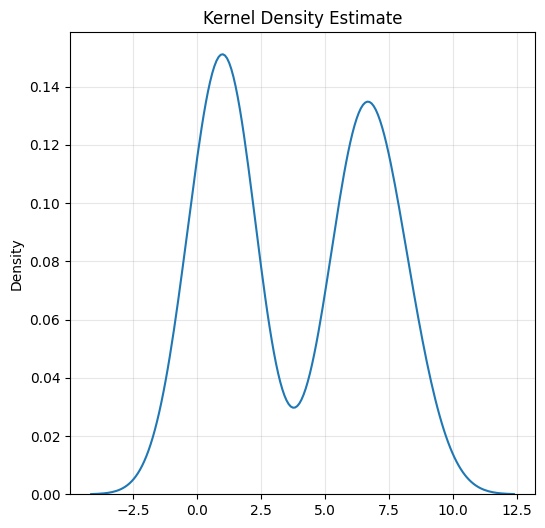

In [12]:
get_kde_plot(input_signal2);

Ok, so I think this is a better signal to separate than the other signal. Let's work with these for now.

## Fitting a GMM
### Finding the optimal number of components to fix

Actually, I got it slightly wrong. The idea appears to be that we fit GMM with a number of components. And metrics like Bayesian Information Criterion (BIC) and Akaike Information Criterion (AIC) will be low when the number of components is closer to the number of original components

## Fitting GMM with multiple values for n_components
Basically doing a grid search here, then

In [13]:
models = []
for i in range(1, 8):
    models.append(GaussianMixture(n_components=i).fit(input_signal2.reshape(-1, 1)))

In [14]:
metric = []
for _, model in enumerate(models):
    metric.append([_ + 1, model.bic(input_signal2.reshape(-1, 1))])

In [18]:
metric_df = pd.DataFrame(metric, columns=["n_components", "bic"])

In [22]:
bic_trend = px.line(
    metric_df, x="n_components", y="bic", title="BIC for various number of components"
)

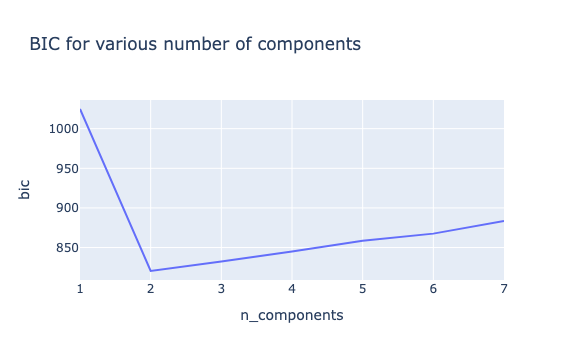

In [23]:
bic_trend.show()

So, across different candidate models (each with different number of components), at `n_components=2`, the BIC is the lowest. 

This is telling us that - a GMM model with 2 components fits the data best. We know this is true because our model only has 2 components.

# What is Bayesian information criterion?

# References
[1] https://www.astroml.org/book_figures/chapter4/fig_GMM_1D.html  
[2] https://scikit-learn.org/stable/modules/mixture.html#gmm